In [ ]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error
import math

# 計算指標

In [ ]:
file_path = "btc_max_ohlc_yfinance.csv"
df = pd.read_csv(file_path)

# 2. 計算移動平均線 (20天 SMA 與 EMA)
df['SMA_20'] = df['Close'].rolling(window=20).mean()
df['EMA_20'] = df['Close'].ewm(span=20, adjust=False).mean()

# 3. 計算 RSI (14天)
delta = df['Close'].diff()
gain = delta.where(delta > 0, 0)
loss = -delta.where(delta < 0, 0)
# 使用 Wilder's 平滑法 (標準 RSI 算法)
avg_gain = gain.ewm(alpha=1/14, adjust=False).mean()
avg_loss = loss.ewm(alpha=1/14, adjust=False).mean()
rs = avg_gain / avg_loss
df['RSI_14'] = 100 - (100 / (1 + rs))

# 4. 計算 MACD (快線12, 慢線26, 訊號線9)
ema_12 = df['Close'].ewm(span=12, adjust=False).mean()
ema_26 = df['Close'].ewm(span=26, adjust=False).mean()
df['MACD_Line'] = ema_12 - ema_26
df['MACD_Signal'] = df['MACD_Line'].ewm(span=9, adjust=False).mean()
df['MACD_Histogram'] = df['MACD_Line'] - df['MACD_Signal']

# 5. 計算每日報酬率
df['Daily_Return'] = df['Close'].pct_change()

# 加密貨幣交易天數設定為 365
trading_days = 365

# 6. 計算整體波動率與夏普值 (單一數值)
overall_volatility = df['Daily_Return'].std() * np.sqrt(trading_days)
mean_annual_return = df['Daily_Return'].mean() * trading_days
overall_sharpe = mean_annual_return / overall_volatility

print(f"整體年化波動率: {overall_volatility:.2%}")
print(f"整體年化夏普值: {overall_sharpe:.2f}")

# 7. 計算滾動波動率與夏普值 (如：觀察過去 365 天的動態變化)
df['Rolling_Vol_365d'] = df['Daily_Return'].rolling(window=14).std() * np.sqrt(trading_days)
df['Rolling_Return_365d'] = df['Daily_Return'].rolling(window=365).mean() * trading_days
df['Rolling_Sharpe_365d'] = df['Rolling_Return_365d'] / df['Rolling_Vol_365d']

# 儲存包含所有指標的新檔案
output_file = "btc_indicators_calculated.csv"
df.to_csv(output_file, index=False)

# 查看自相關和偏自相關

In [ ]:
# 1. 讀取與整理資料
df = pd.read_csv("btc_max_ohlc_yfinance.csv")
df['Date'] = pd.to_datetime(df['Date'], utc=True)
df = df.sort_values('Date').reset_index(drop=True)

# 2. 轉換為報酬率 (讓序列平穩化)
df['Daily_Return'] = df['Close'].pct_change()
returns = df['Daily_Return'].dropna()

# 3. 計算並取得 ACF 與 PACF 的「具體數值」 (用於機器學習特徵提取)
# nlags=40 代表計算到過去 40 天
acf_values = sm.tsa.stattools.acf(returns, nlags=40)
pacf_values = sm.tsa.stattools.pacf(returns, nlags=40, method='ywm')

# 將計算結果建立成 DataFrame 以便觀察或合併到原資料集
correlation_df = pd.DataFrame({
    'Lag': range(41),
    'ACF': acf_values,
    'PACF': pacf_values
})
print(correlation_df.head())

# 4. 繪製 ACF / PACF 圖像 (用於人工判斷 ARIMA 模型的 p, q 參數)
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# 繪製 ACF (判斷 MA 模型的 q 參數)
plot_acf(returns, ax=axes[0], lags=40, title='Autocorrelation (ACF) of BTC Daily Returns')
axes[0].set_xlabel('Lags')
axes[0].set_ylabel('ACF')

# 繪製 PACF (判斷 AR 模型的 p 參數)
plot_pacf(returns, ax=axes[1], lags=40, title='Partial Autocorrelation (PACF) of BTC Daily Returns', method='ywm')
axes[1].set_xlabel('Lags')
axes[1].set_ylabel('PACF')

plt.tight_layout()
plt.show()

In [ ]:
# 1. 讀取與整理資料
df = pd.read_csv("btc_max_ohlc_yfinance.csv")
df['Date'] = pd.to_datetime(df['Date'], utc=True)
df = df.sort_values('Date').reset_index(drop=True)

returns = df['Close'].dropna()

# 3. 計算並取得 ACF 與 PACF 的「具體數值」 (用於機器學習特徵提取)
# nlags=40 代表計算到過去 40 天
acf_values = sm.tsa.stattools.acf(returns, nlags=40)
pacf_values = sm.tsa.stattools.pacf(returns, nlags=40, method='ywm')

# 將計算結果建立成 DataFrame 以便觀察或合併到原資料集
correlation_df = pd.DataFrame({
    'Lag': range(41),
    'ACF': acf_values,
    'PACF': pacf_values
})
print(correlation_df.head())

# 4. 繪製 ACF / PACF 圖像 (用於人工判斷 ARIMA 模型的 p, q 參數)
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# 繪製 ACF (判斷 MA 模型的 q 參數)
plot_acf(returns, ax=axes[0], lags=40, title='Autocorrelation (ACF) of BTC Close price')
axes[0].set_xlabel('Lags')
axes[0].set_ylabel('ACF')

# 繪製 PACF (判斷 AR 模型的 p 參數)
plot_pacf(returns, ax=axes[1], lags=40, title='Partial Autocorrelation (PACF) of BTC Close price', method='ywm')
axes[1].set_xlabel('Lags')
axes[1].set_ylabel('PACF')

plt.tight_layout()
plt.show()

# Transformer 實驗（v3：依老師修改建議）

| 老師建議 | 這份程式的做法 |
|---|---|
| #1 Naive persistence | 「明日 = 今日」，和模型用**同一批目標日期**；train / val / test 都算 |
| #2 資料洩漏 | scaler **只用訓練區擬合**；驗證集 = 訓練區最後 10%（**72 / 8 / 20**，train : test 仍是 80 : 20）；用驗證 loss 選 epoch；**訓練過程完全不碰測試集**，最後只評估一次 |
| #3 多 seed | seed **0–4**；平均 ± 標準差、每組最小～最大值；老師指定的比較自動判斷「明顯較好／comparable」並附 paired t-test |
| #5 Table II | 自動產生 `table2_settings.csv`（預熱期刪除天數、batch、版本、GPU…） |
| #6 指標 | RMSE、MAE、MAPE（另有 MSE），依 test RMSE 排序 |
| #7 圖 | x 軸日期、loss 對數刻度、**60 天放大圖**（實際／persistence／Close-only／最佳組合同一張） |
| #8 train/test 差距 | 輸出訓練期與測試期最高價、每組測試期最高預測值 |
| #11 組合 | Close + 5 組指標（**MACD3 算一組**）所有組合：2⁵ = **32 組 × 5 seeds = 160 次** |
| #15 方向命中率 | Directional accuracy（預測漲跌方向與實際相同的比例） |

**使用方式**
1. 執行階段 → 變更執行階段類型 → **T4 GPU**
2. 確認 `btc_indicators_calculated.csv` 在 Colab（上面「計算指標」那格會產生，也可以直接上傳）
3. 從頭依序執行。結果每跑完一次就存到 Google Drive；**斷線後重新執行會自動略過已完成的部分**
4. 執行順序是：老師指定的 4 組 → 報告 Table IV 的其餘 6 組 → 剩下 22 組。中途停下來，也會先有最重要的結果
5. 統計和畫圖的格子隨時都能跑，會用目前已完成的結果

In [1]:
# ==========================================
# 實驗設定（要調整只需改這一格）
# ==========================================
import os, sys, json, math, time, random, platform, subprocess, warnings
from itertools import combinations
from pathlib import Path
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import FuncFormatter
from sklearn.preprocessing import MinMaxScaler

warnings.filterwarnings('ignore', message='enable_nested_tensor')

# ---- 結果存放位置：存到 Google Drive，Colab 斷線後重跑會自動略過已完成的組合 ----
USE_DRIVE = True
if USE_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
    BASE_DIR = Path('/content/drive/MyDrive/btc_transformer_results')
else:
    BASE_DIR = Path('btc_transformer_results')

DATA_PATH = 'btc_indicators_calculated.csv'   # 由「計算指標」那格產生，或直接上傳
END_DATE = None    # None = 用 CSV 全部資料（目前到 2026-05-12）；要和報告寫的日期一致可設 '2026-05-10'

# ---- 特徵：Close 一定包含；5 組候選指標（MACD 三條線算一組）→ 2^5 = 32 種組合 ----
TARGET_COL = 'Close'
FEATURE_GROUPS = {                      # 報告用名稱 → CSV 欄位
    'MACD3':   ['MACD_Line', 'MACD_Signal', 'MACD_Histogram'],
    'RSI(14)': ['RSI_14'],
    'SMA(20)': ['SMA_20'],
    'EMA(20)': ['EMA_20'],
    'Return':  ['Daily_Return'],
}
GROUP_ORDER = list(FEATURE_GROUPS)

PRIORITY = [                            # 老師指定的 4 組關鍵組合
    [],
    ['MACD3', 'Return'],
    ['MACD3', 'RSI(14)'],
    ['MACD3', 'RSI(14)', 'Return'],
]
TABLE4 = [                              # 報告 Table IV 原本的 10 組
    [], ['RSI(14)'], ['EMA(20)'], ['SMA(20)'], ['MACD3'], ['RSI(14)', 'Return'],
    ['MACD3', 'RSI(14)'], ['MACD3', 'RSI(14)', 'Return'], ['MACD3', 'Return'], ['Return'],
]
COMPARISONS = [                         # 老師要判斷「有沒有差」的比較 (A, B)
    ([], ['MACD3', 'Return']),
    (['RSI(14)'], ['RSI(14)', 'Return']),
    (['RSI(14)'], ['MACD3']),
    ([], ['SMA(20)']),
    (['MACD3', 'Return'], ['MACD3', 'RSI(14)', 'Return']),
]

RUN_SCOPE = 'all'          # 'priority' = 4 組（20 次）｜'table4' = 報告的 10 組（50 次）｜'all' = 32 組（160 次）
SEEDS = [0, 1, 2, 3, 4]

# ---- 時間序列切分（依「預測目標日期」先後）----
LOOKBACK = 60
TEST_FRAC = 0.20     # 測試集 = 最後 20%（train : test = 80 : 20，與先前實驗相同）
VAL_FRAC = 0.10      # 驗證集 = 訓練區（前 80%）的最後 10% → 72 / 8 / 20；設 0 則不切驗證集

# ---- 模型與訓練（架構、超參數與原本相同）----
NUM_LAYERS, NHEAD, HIDDEN_DIM, DROPOUT = 2, 4, 128, 0.1
LR = 0.001
NUM_EPOCHS = 300
SELECT_BEST_VAL = True     # 用驗證 loss 最低那個 epoch 的權重預測；VAL_FRAC = 0 時固定用最後一個 epoch

USE_VAL = VAL_FRAC > 0
RECORD_TEST_LOSS = not USE_VAL   # 有驗證集時訓練過程完全不碰測試集；沒有驗證集時才記錄 test loss（只畫圖）

# ---- 結果資料夾（不同切分設定分開存，避免混在一起續跑）----
SPLIT_PCTS = (round(100 * (1 - TEST_FRAC) * (1 - VAL_FRAC)), round(100 * (1 - TEST_FRAC) * VAL_FRAC), round(100 * TEST_FRAC))
SPLIT_TAG = 'v3_split_{}-{}-{}'.format(*SPLIT_PCTS)
OUT_DIR = BASE_DIR / SPLIT_TAG
PRED_DIR, LOSS_DIR, FIG_DIR = OUT_DIR / 'predictions', OUT_DIR / 'loss', OUT_DIR / 'figures'
for d in (PRED_DIR, LOSS_DIR, FIG_DIR):
    d.mkdir(parents=True, exist_ok=True)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('使用設備：', device, '｜結果資料夾：', OUT_DIR)
if device.type == 'cpu':
    print('⚠️ 目前沒有 GPU：請到「執行階段 → 變更執行階段類型」選 T4 GPU')

# ---- 組合命名 ----
def combo_name(groups):
    s = set(groups)
    return ' + '.join(['Close'] + [g for g in GROUP_ORDER if g in s])

def combo_key(groups):          # 檔名用
    return combo_name(groups).replace(' + ', '_').replace('(', '').replace(')', '')

def combo_columns(groups):
    s = set(groups)
    return [TARGET_COL] + [c for g in GROUP_ORDER if g in s for c in FEATURE_GROUPS[g]]

def dedupe(combos):
    seen, out = set(), []
    for c in combos:
        if combo_name(c) not in seen:
            seen.add(combo_name(c)); out.append(c)
    return out

ALL_COLS = combo_columns(GROUP_ORDER)
ALL_COMBOS = [list(c) for r in range(len(GROUP_ORDER) + 1) for c in combinations(GROUP_ORDER, r)]
SCOPES = {'priority': PRIORITY,
          'table4':   dedupe(PRIORITY + TABLE4),
          'all':      dedupe(PRIORITY + TABLE4 + ALL_COMBOS)}     # 重要的先跑
PRIORITY_NAMES = [combo_name(c) for c in PRIORITY]
TABLE4_NAMES = [combo_name(c) for c in TABLE4]
ALL_NAMES = [combo_name(c) for c in ALL_COMBOS]
BEST_NAME, BASE_NAME = combo_name(['MACD3', 'Return']), combo_name([])
print(f"切分 {SPLIT_PCTS[0]} / {SPLIT_PCTS[1]} / {SPLIT_PCTS[2]}｜範圍 {RUN_SCOPE}：{len(SCOPES[RUN_SCOPE])} 組 × {len(SEEDS)} seeds = {len(SCOPES[RUN_SCOPE]) * len(SEEDS)} 次")

Mounted at /content/drive
使用設備： cuda ｜結果資料夾： /content/drive/MyDrive/btc_transformer_results/v3_split_72-8-20
切分 72 / 8 / 20｜範圍 all：32 組 × 5 seeds = 160 次


## 執行環境紀錄
每次開新的 Colab session 都會在 `environment_log.jsonl` 追加一筆；每次實驗的 GPU 型號也寫進 `runs_metrics.csv`（跨 session 可能分到不同 GPU）。

In [2]:
import sklearn, matplotlib, statsmodels, scipy

def collect_environment():
    cuda = torch.cuda.is_available()
    env = {
        'recorded_at':      pd.Timestamp.now(tz='Asia/Taipei').isoformat(timespec='seconds'),
        'python':           sys.version.split()[0],
        'platform':         platform.platform(),
        'torch':            torch.__version__,
        'torch_cuda_build': torch.version.cuda,
        'cudnn':            torch.backends.cudnn.version() if cuda else None,
        'numpy':            np.__version__,
        'pandas':           pd.__version__,
        'scikit-learn':     sklearn.__version__,
        'scipy':            scipy.__version__,
        'matplotlib':       matplotlib.__version__,
        'statsmodels':      statsmodels.__version__,
        'device':           str(device),
        'gpu':              torch.cuda.get_device_name(0) if cuda else 'CPU only',
    }
    try:
        env['nvidia_smi'] = subprocess.run(
            ['nvidia-smi', '--query-gpu=name,memory.total,driver_version', '--format=csv,noheader'],
            capture_output=True, text=True, timeout=10).stdout.strip() or None
    except Exception:
        env['nvidia_smi'] = None
    return env

ENV = collect_environment()
with open(OUT_DIR / 'environment_log.jsonl', 'a', encoding='utf-8') as f:
    f.write(json.dumps(ENV, ensure_ascii=False) + '\n')
for k, v in ENV.items():
    print(f'{k:17s}: {v}')

recorded_at      : 2026-11-21T19:18:37+08:00
python           : 3.13.16
platform         : Linux-6.6.159+-x86_64-with-glibc2.39
torch            : 2.14.1+cu130
torch_cuda_build : 13.0
cudnn            : 92800
numpy            : 2.4.6
pandas           : 2.2.3
scikit-learn     : 1.6.1
scipy            : 1.16.3
matplotlib       : 3.10.0
statsmodels      : 0.15.0
device           : cuda
gpu              : Tesla T4
nvidia_smi       : Tesla T4, 15360 MiB, 580.82.07


## 資料準備
- 刪掉指標暖機期（8 個欄位任一為空值的日期，主要是 SMA_20 的前 19 天），**所有組合共用同一批日期**
- 依預測目標日期：前 80% 為訓練區、後 20% 為測試集；訓練區最後 10% 再切成驗證集（72 / 8 / 20）
- **scaler 只用訓練集擬合**（不含驗證集與測試集），驗證集與測試集只做 transform
- 基準：明日價格 = 今日價格（Naive persistence）
- 自動產生報告 Table II 需要的設定值 `table2_settings.csv`

In [3]:
raw = pd.read_csv(DATA_PATH)
raw['Date'] = pd.to_datetime(raw['Date'].astype(str).str[:10])
raw = raw.sort_values('Date').reset_index(drop=True)
if END_DATE:
    raw = raw[raw['Date'] <= pd.Timestamp(END_DATE)].reset_index(drop=True)

df = raw.dropna(subset=ALL_COLS).reset_index(drop=True)
n_warmup = int((raw['Date'] < df['Date'].iloc[0]).sum())         # 指標暖機期刪掉的天數
n_dropped_other = len(raw) - len(df) - n_warmup
if n_dropped_other:
    print(f'⚠️ 暖機期之後還有 {n_dropped_other} 天有空值被刪除')

n_samples = len(df) - LOOKBACK
n_trainval = int(n_samples * (1 - TEST_FRAC))      # 與原本 train_size = int(len(X) * 0.8) 相同
n_train = int(n_trainval * (1 - VAL_FRAC))         # 訓練區的前 90%
n_val = n_trainval - n_train                       # 訓練區的最後 10%
n_test = n_samples - n_trainval
SPLITS = ['train', 'val', 'test'] if USE_VAL else ['train', 'test']
SPLIT_LABEL = {'train': 'Train', 'val': 'Validation', 'test': 'Test'}

target_rows = np.arange(LOOKBACK, len(df))                     # 第 k 個樣本要預測的那一天（列號）
split = np.array(['train'] * n_train + ['val'] * n_val + ['test'] * n_test)
train_last_row = target_rows[n_train - 1]

# ---- 修正資料洩漏：scaler 只看訓練集 ----
scaler_X = MinMaxScaler(feature_range=(0, 1)).fit(df.loc[:train_last_row, ALL_COLS].values)
scaler_y = MinMaxScaler(feature_range=(0, 1)).fit(df.loc[target_rows[:n_train], [TARGET_COL]].values)
X_scaled = scaler_X.transform(df[ALL_COLS].values).astype(np.float32)
y_scaled = scaler_y.transform(df[[TARGET_COL]].values).astype(np.float32)[:, 0]

# 滑動視窗：用前 LOOKBACK 天（不含當天）預測當天收盤價，與原本 create_sequences 相同
windows = np.stack([X_scaled[r - LOOKBACK:r] for r in target_rows])     # (樣本數, LOOKBACK, 欄位數)
y_target = y_scaled[target_rows]

close = df[TARGET_COL].values
samples = pd.DataFrame({
    'target_date': df['Date'].values[target_rows],
    'split':       split,
    'actual':      close[target_rows],
    'naive':       close[target_rows - 1],     # Naive persistence：視窗最後一天（今天）的收盤價
})

def calc_metrics(actual, pred, prev_close=None):
    actual, pred = np.asarray(actual, float), np.asarray(pred, float)
    err = pred - actual
    m = {'MSE':  float(np.mean(err ** 2)),
         'RMSE': float(np.sqrt(np.mean(err ** 2))),
         'MAE':  float(np.mean(np.abs(err))),
         'MAPE': float(np.mean(np.abs(err) / np.abs(actual)) * 100)}
    if prev_close is not None:     # 方向命中率：預測的漲跌方向（相對今天收盤價）與實際相同的比例
        prev_close = np.asarray(prev_close, float)
        m['DirAcc'] = float(np.mean(np.sign(actual - prev_close) == np.sign(pred - prev_close)) * 100)
    else:
        m['DirAcc'] = np.nan
    return m

# Naive 永遠預測「不變」，方向命中率沒有意義，記為空值
naive_metrics = {sp: calc_metrics(samples.loc[samples.split == sp, 'actual'],
                                  samples.loc[samples.split == sp, 'naive']) for sp in SPLITS}
(samples[['target_date', 'split', 'actual', 'naive']]
    .rename(columns={'naive': 'predicted'})
    .assign(model='Naive persistence (tomorrow = today)')
    .to_csv(OUT_DIR / 'naive_baseline_predictions.csv', index=False))

# ---- 切分資訊 ----
split_info = {'data_first_date': f"{raw['Date'].iloc[0]:%Y-%m-%d}", 'data_last_date': f"{raw['Date'].iloc[-1]:%Y-%m-%d}",
              'raw_rows': int(len(raw)), 'warmup_rows_removed': n_warmup,
              'first_retained_date': f"{df['Date'].iloc[0]:%Y-%m-%d}", 'lookback': LOOKBACK}
for sp in SPLITS:
    g = samples[samples.split == sp]
    split_info[sp] = {'n_windows': int(len(g)),
                      'first_target_date': f'{g.target_date.min():%Y-%m-%d}',
                      'last_target_date':  f'{g.target_date.max():%Y-%m-%d}',
                      'close_min': float(g.actual.min()), 'close_max': float(g.actual.max()),
                      'close_max_date': f"{g.target_date.iloc[int(g.actual.values.argmax())]:%Y-%m-%d}"}
    print(f"{SPLIT_LABEL[sp]:10s} {len(g):5d} 天  {split_info[sp]['first_target_date']} ~ {split_info[sp]['last_target_date']}"
          f"   Close {g.actual.min():>10,.0f} ~ {g.actual.max():>10,.0f}（最高 {split_info[sp]['close_max_date']}）")
train_max = float(scaler_y.data_max_[0])
pct_above = float((samples.loc[samples.split == 'test', 'actual'] > train_max).mean() * 100)
split_info.update({'scaler_upper_bound_train_close_max': train_max, 'test_days_above_train_max_pct': pct_above})
with open(OUT_DIR / 'split_info.json', 'w') as f:
    json.dump(split_info, f, indent=2)

print(f'\n資料 {split_info["data_first_date"]} ~ {split_info["data_last_date"]}，暖機期刪除前 {n_warmup} 天（從 {split_info["first_retained_date"]} 開始）')
print(f'訓練集最高收盤價（scaler 上限）：{train_max:,.0f}；測試期有 {pct_above:.1f}% 的天數高於此值 → 模型必須外插')

# ---- 報告 Table II 的設定值 ----
date_fmt = lambda d: f'{d:%B} {d.day}, {d:%Y}'
table2 = pd.DataFrame([
    ('Data and target', f"Daily BTC-USD (Yahoo Finance), {date_fmt(raw['Date'].iloc[0])}–{date_fmt(raw['Date'].iloc[-1])}; next-day closing price"),
    ('Input window L', f'{LOOKBACK} days'),
    ('Training / validation / test split',
     f'Chronological by target date; {SPLIT_PCTS[0]} / {SPLIT_PCTS[1]} / {SPLIT_PCTS[2]}% '
     f'({n_train:,} / {n_val:,} / {n_test:,} windows)' if USE_VAL else
     f'Chronological by target date; 80 / 20% ({n_train:,} / {n_test:,} windows)'),
    ('Scaling', 'MinMaxScaler (0–1) fitted on the training partition only; applied unchanged to validation and test'
                if USE_VAL else 'MinMaxScaler (0–1) fitted on the training partition only; applied unchanged to test'),
    ('Validation', 'Last 10% of the training partition (chronological); used to select the epoch with the lowest validation MSE'
                   if USE_VAL and SELECT_BEST_VAL else ('Last 10% of the training partition; monitored only' if USE_VAL else 'None')),
    ('Test usage', 'Evaluated once after training; never used for model, epoch, or hyperparameter selection' if USE_VAL
                   else 'Test loss recorded each epoch for plotting only; final-epoch model evaluated'),
    ('Hidden dimension / heads / layers', f'{HIDDEN_DIM} / {NHEAD} / {NUM_LAYERS} (feed-forward width {HIDDEN_DIM})'),
    ('Dropout', f'{DROPOUT}'),
    ('Optimizer / learning rate / batch size', f'Adam / {LR} / full batch ({n_train:,} training windows)'),
    ('Training loss / epochs', f'MSE / {NUM_EPOCHS}'),
    ('Technical indicators', 'SMA(20), EMA(20), RSI(14, Wilder smoothing), MACD(12, 26, 9)'),
    ('Daily Return', '(Close_t − Close_{t−1}) / Close_{t−1}'),
    ('Warm-up rows removed', f"First {n_warmup} days (indicator values undefined); first retained date {date_fmt(df['Date'].iloc[0])}"),
    ('Random seeds', f'{SEEDS[0]}–{SEEDS[-1]}' if SEEDS == list(range(SEEDS[0], SEEDS[-1] + 1)) else ', '.join(map(str, SEEDS))),
    ('Framework / hardware', f"PyTorch {ENV['torch']} (CUDA {ENV['torch_cuda_build']}) / {ENV['gpu']}"),
], columns=['Setting', 'Value'])
table2.to_csv(OUT_DIR / 'table2_settings.csv', index=False)
print('\nTable II 設定值：'); display(table2)

print('Naive persistence：')
display(pd.DataFrame(naive_metrics).T.drop(columns='DirAcc')
        .style.format({'MSE': '{:.3e}', 'RMSE': '{:,.0f}', 'MAE': '{:,.0f}', 'MAPE': '{:.2f}'}))

Train       3006 天  2014-12-05 ~ 2023-02-26   Close        178 ~     67,567（最高 2021-11-08）
Validation   335 天  2023-02-27 ~ 2024-01-27   Close     20,187 ~     46,971（最高 2024-01-08）
Test         836 天  2024-01-28 ~ 2026-05-12   Close     42,036 ~    124,753（最高 2025-10-06）

資料 2014-09-17 ~ 2026-05-12，暖機期刪除前 19 天（從 2014-10-06 開始）
訓練集最高收盤價（scaler 上限）：67,567；測試期有 71.9% 的天數高於此值 → 模型必須外插

Table II 設定值：


,Setting,Value
0,Data and target,"Daily BTC-USD (Yahoo Finance), September 17, 2..."
1,Input window L,60 days
2,Training / validation / test split,"Chronological by target date; 72 / 8 / 20% (3,..."
3,Scaling,MinMaxScaler (0–1) fitted on the training part...
4,Validation,Last 10% of the training partition (chronologi...
5,Test usage,Evaluated once after training; never used for ...
6,Hidden dimension / heads / layers,128 / 4 / 2 (feed-forward width 128)
7,Dropout,0.1
8,Optimizer / learning rate / batch size,"Adam / 0.001 / full batch (3,006 training wind..."
9,Training loss / epochs,MSE / 300


Naive persistence：


,MSE,RMSE,MAE,MAPE
train,6.425e+05,802,366,2.52
val,5.511e+05,742,485,1.53
test,4.099e+06,"2,025","1,457",1.80


In [4]:
# ==========================================
# 儲存每次實驗結果（支援中斷續跑）
# ==========================================
RUNS_CSV = OUT_DIR / 'runs_metrics.csv'

def completed_runs():
    if not RUNS_CSV.exists():
        return set()
    r = pd.read_csv(RUNS_CSV)
    return set(zip(r['combo'], r['seed']))

def record_run(groups, seed, pred_usd, loss_hist, best_epoch, train_time):
    """存逐日預測、每個 epoch 的 loss，並把指標追加到 runs_metrics.csv（最後才寫，確保中斷時會重跑）"""
    name, key = combo_name(groups), combo_key(groups)
    pred_df = samples[['target_date', 'split', 'actual']].copy()
    pred_df['predicted'] = pred_usd
    pred_df['combo'] = name
    pred_df['seed'] = seed
    pred_df.to_csv(PRED_DIR / f'{key}__seed{seed}.csv', index=False)

    pd.DataFrame(loss_hist, columns=['epoch', 'train_loss', 'val_loss', 'test_loss']) \
      .to_csv(LOSS_DIR / f'{key}__seed{seed}.csv', index=False)

    row = {'combo': name, 'combo_key': key, 'n_groups': len(groups), 'F': len(combo_columns(groups)),
           'features': '|'.join(combo_columns(groups)), 'seed': seed,
           'epochs': len(loss_hist), 'best_epoch': best_epoch,
           'selected_weights': 'best_val_epoch' if (USE_VAL and SELECT_BEST_VAL) else 'last_epoch',
           'train_time_s': round(train_time, 1), 'gpu': ENV['gpu']}
    for sp in SPLITS:
        m = (pred_df['split'] == sp).values
        for k, v in calc_metrics(pred_df.loc[m, 'actual'], pred_df.loc[m, 'predicted'],
                                 samples.loc[m, 'naive']).items():
            row[f'{sp}_{k}'] = v
    row['test_pred_max'] = float(pred_df.loc[pred_df.split == 'test', 'predicted'].max())
    pd.DataFrame([row]).to_csv(RUNS_CSV, mode='a', header=not RUNS_CSV.exists(), index=False)
    return row

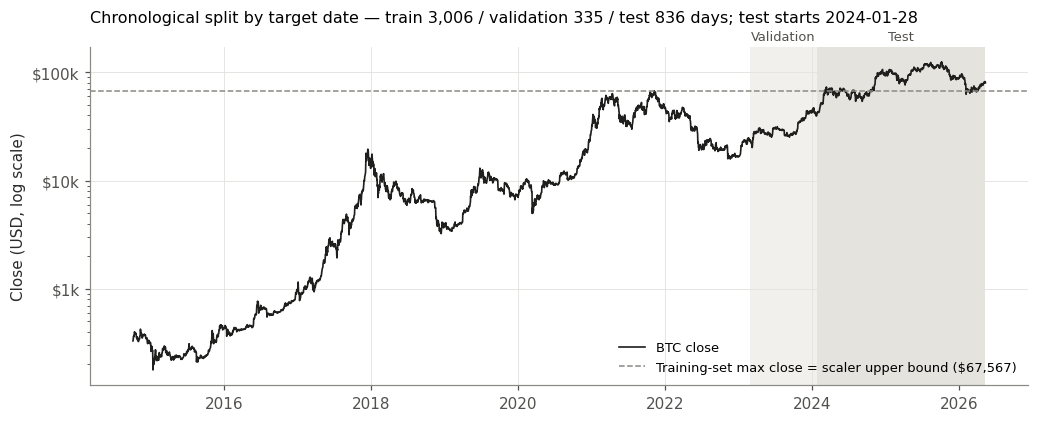

In [5]:
# ==========================================
# 圖表共用設定（報告用英文標籤，避免 Colab 中文字型變方塊）
# ==========================================
plt.rcParams.update({
    'figure.dpi': 110, 'savefig.dpi': 200, 'font.size': 10,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': '#e4e3df', 'grid.linewidth': 0.6,
    'axes.edgecolor': '#8a8984', 'axes.labelcolor': '#2b2b2a', 'axes.titlesize': 10.5,
    'xtick.color': '#52514e', 'ytick.color': '#52514e',
    'legend.frameon': False, 'legend.fontsize': 8.5, 'lines.linewidth': 1.5,
})
COL_ACTUAL = '#1f1f1e'      # 實際價格
COL_NAIVE = '#8a8984'       # persistence / 參考線
COL_TRAIN = '#52514e'       # 訓練 loss
COL_OTHER = '#a9a8a2'       # 非優先組合
COMBO_COLORS = dict(zip(PRIORITY_NAMES, ['#2a78d6', '#eb6834', '#1baf7a', '#eda100']))

SPLIT_BOUNDS = {sp: (samples.loc[samples.split == sp, 'target_date'].min(),
                     samples.loc[samples.split == sp, 'target_date'].max()) for sp in SPLITS}
usd_k = FuncFormatter(lambda v, _: f'${v/1000:,.0f}k' if v >= 1000 else f'${v:,.0f}')
wrap = lambda name: name.replace(' + ', '\n+ ')

def shade_splits(ax, label=True):
    for sp, c in [('val', '#f1f0ec'), ('test', '#e4e3de')]:
        if sp not in SPLITS:
            continue
        a, b = SPLIT_BOUNDS[sp]
        ax.axvspan(a, b, color=c, zorder=0, lw=0)
        if label:
            ax.text(a + (b - a) / 2, 1.01, SPLIT_LABEL[sp], transform=ax.get_xaxis_transform(),
                    ha='center', va='bottom', fontsize=8.5, color='#52514e')

def date_axis(ax):
    loc = mdates.AutoDateLocator()
    ax.xaxis.set_major_locator(loc)
    ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(loc))

def save(fig, name):
    fig.savefig(FIG_DIR / name, bbox_inches='tight')
    plt.show()

# ---- 圖 1：資料切分 ----
fig, ax = plt.subplots(figsize=(11, 4))
shade_splits(ax)
ax.plot(df['Date'], df['Close'], color=COL_ACTUAL, lw=1.1, label='BTC close')
ax.axhline(train_max, color=COL_NAIVE, ls='--', lw=1,
           label=f'Training-set max close = scaler upper bound (${train_max:,.0f})')
ax.set_yscale('log')
ax.yaxis.set_major_formatter(usd_k)
ax.set_ylabel('Close (USD, log scale)')
date_axis(ax)
split_txt = ' / '.join(f'{SPLIT_LABEL[sp].lower()} {split_info[sp]["n_windows"]:,}' for sp in SPLITS)
ax.set_title(f'Chronological split by target date — {split_txt} days; test starts {split_info["test"]["first_target_date"]}',
             loc='left', pad=16)
ax.legend(loc='lower right')
save(fig, '01_data_split.png')

## 模型與單次實驗
模型架構與原本完全相同。每個 epoch 記錄（loss 都在縮放後 0–1 的尺度）：
- `train_loss`：訓練模式（有 dropout）下的訓練集 MSE，也就是實際被最佳化的 loss
- `val_loss`：驗證集 MSE，用來挑選最佳 epoch
- `test_loss`：**有驗證集時不計算**（訓練過程完全不碰測試集，測試集只在訓練完評估一次）；`VAL_FRAC = 0` 時才記錄，只用來畫圖，圖上標示為 Test loss

In [6]:
class PositionalEncoding(nn.Module):
    def __init__(self, d_model, max_len=5000):
        super(PositionalEncoding, self).__init__()
        pe = torch.zeros(max_len, d_model)
        position = torch.arange(0, max_len).unsqueeze(1).float()
        div_term = torch.exp(torch.arange(0, d_model, 2).float() * (-math.log(10000.0) / d_model))
        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)
        pe = pe.unsqueeze(1)
        self.register_buffer('pe', pe)

    def forward(self, x):
        x = x + self.pe[:x.size(0)]
        return x

class TransformerTimeSeries(nn.Module):
    def __init__(self, feature_size=1, num_layers=2, nhead=4, hidden_dim=128, dropout=0.1):
        super(TransformerTimeSeries, self).__init__()
        self.model_type = 'Transformer'
        self.input_linear = nn.Linear(feature_size, hidden_dim)
        self.pos_encoder = PositionalEncoding(d_model=hidden_dim)
        encoder_layers = nn.TransformerEncoderLayer(d_model=hidden_dim, nhead=nhead, dim_feedforward=hidden_dim, dropout=dropout)
        self.transformer_encoder = nn.TransformerEncoder(encoder_layers, num_layers=num_layers)
        self.decoder = nn.Linear(hidden_dim, 1)
        self.hidden_dim = hidden_dim

    def forward(self, src):
        src = self.input_linear(src)
        src = self.pos_encoder(src)
        output = self.transformer_encoder(src)
        # 取最後一個時間步的輸出
        output = self.decoder(output[-1, :, :])
        return output

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

# 所有視窗一次搬上 GPU，形狀 (seq_len, 樣本數, 欄位數)，各組合再挑欄位
X_all_t = torch.from_numpy(windows).permute(1, 0, 2).contiguous().to(device)
y_all_t = torch.from_numpy(y_target).to(device)
SL = {'train': slice(0, n_train), 'val': slice(n_train, n_trainval), 'test': slice(n_trainval, n_samples)}

def run_experiment(groups, seed):
    set_seed(seed)
    col_idx = [ALL_COLS.index(c) for c in combo_columns(groups)]
    X = X_all_t.index_select(2, torch.tensor(col_idx, device=device))
    Xtr, ytr = X[:, SL['train']], y_all_t[SL['train']]
    if USE_VAL:
        Xva, yva = X[:, SL['val']], y_all_t[SL['val']]
    if RECORD_TEST_LOSS:
        Xte, yte = X[:, SL['test']], y_all_t[SL['test']]

    model = TransformerTimeSeries(feature_size=len(col_idx), num_layers=NUM_LAYERS, nhead=NHEAD,
                                  hidden_dim=HIDDEN_DIM, dropout=DROPOUT).to(device)
    criterion = nn.MSELoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=LR)

    hist, best_val, best_epoch, best_state = [], float('inf'), None, None
    t0 = time.time()
    for epoch in range(1, NUM_EPOCHS + 1):
        model.train()
        optimizer.zero_grad()
        loss = criterion(model(Xtr).squeeze(-1), ytr)
        loss.backward()
        optimizer.step()

        model.eval()
        with torch.no_grad():
            val_loss = criterion(model(Xva).squeeze(-1), yva).item() if USE_VAL else float('nan')
            test_loss = criterion(model(Xte).squeeze(-1), yte).item() if RECORD_TEST_LOSS else float('nan')
        hist.append((epoch, loss.item(), val_loss, test_loss))
        if USE_VAL and val_loss < best_val:
            best_val, best_epoch = val_loss, epoch
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}

    if USE_VAL and SELECT_BEST_VAL:
        model.load_state_dict(best_state)
    model.eval()
    with torch.no_grad():                       # 訓練完成後才第一次（也是唯一一次）預測測試集
        pred_scaled = model(X).squeeze(-1).cpu().numpy()
    pred_usd = scaler_y.inverse_transform(pred_scaled.reshape(-1, 1))[:, 0]
    return pred_usd, hist, best_epoch, time.time() - t0

## 批次執行（可中斷續跑）
已完成的 (組合, seed) 會從 Drive 上的 `runs_metrics.csv` 讀取並略過。Colab 斷線後重新連線，從頭依序執行到這格即可接著跑。第一次的執行時間可以用來估算總時數（老師建議：先計時一次）。

In [7]:
done = completed_runs()
combos = SCOPES[RUN_SCOPE]
todo = [(c, s) for c in combos for s in SEEDS if (combo_name(c), s) not in done]
total = len(combos) * len(SEEDS)
print(f'範圍：{RUN_SCOPE}｜共 {total} 次，已完成 {total - len(todo)}，待跑 {len(todo)}')

t_start = time.time()
for i, (groups, seed) in enumerate(todo, 1):
    pred_usd, hist, best_epoch, sec = run_experiment(groups, seed)
    row = record_run(groups, seed, pred_usd, hist, best_epoch, sec)
    eta_min = (time.time() - t_start) / i * (len(todo) - i) / 60
    be_txt = f'best_val_epoch={best_epoch:3d}  ' if best_epoch else ''
    print(f"[{i:3d}/{len(todo)}] {row['combo']:<50s} seed={seed}  {be_txt}"
          f"test RMSE={row['test_RMSE']:>8,.0f}  MAPE={row['test_MAPE']:6.2f}%  ({sec:.0f}s，剩餘約 {eta_min:.0f} 分)")
print('完成')

範圍：all｜共 160 次，已完成 0，待跑 160
[  1/160] Close                                              seed=0  best_val_epoch=299  test RMSE=  12,350  MAPE=  9.89%  (59s，剩餘約 171 分)
[  2/160] Close                                              seed=1  best_val_epoch=242  test RMSE=   9,582  MAPE=  7.19%  (63s，剩餘約 168 分)
[  3/160] Close                                              seed=2  best_val_epoch=295  test RMSE=  12,631  MAPE= 10.16%  (65s，剩餘約 168 分)
[  4/160] Close                                              seed=3  best_val_epoch=300  test RMSE=  11,970  MAPE=  9.82%  (65s，剩餘約 168 分)
[  5/160] Close                                              seed=4  best_val_epoch=276  test RMSE=  11,834  MAPE=  9.46%  (65s，剩餘約 167 分)
[  6/160] Close + MACD3 + Return                             seed=0  best_val_epoch=298  test RMSE=   5,773  MAPE=  4.72%  (65s，剩餘約 166 分)
[  7/160] Close + MACD3 + Return                             seed=1  best_val_epoch=289  test RMSE=   5,130  MAPE=  3.99%  (65s，剩餘約 165 分)

## 彙整結果
- `metrics_summary_all.csv`：每個組合各 split 的平均與標準差（樣本標準差，ddof = 1）、test RMSE 最小～最大值、依 test RMSE 排序
- `table4_ten_configs.csv`：報告 Table IV 的 10 組 + Naive（依 test RMSE 排序；未跑滿 5 個 seed 的組合標 †）
- `table_all_32_configs.csv`：32 組 + Naive
- `comparisons.csv`：老師指定的比較（平均差距 vs 兩組標準差和、paired t-test）

In [10]:
runs = pd.read_csv(RUNS_CSV).drop_duplicates(['combo', 'seed'], keep='last')
runs = runs[runs.combo.isin(ALL_NAMES) & runs.seed.isin(SEEDS)]
METRICS = ['MSE', 'RMSE', 'MAE', 'MAPE', 'DirAcc']

agg = {}
for sp in SPLITS:
    for m in METRICS:
        agg[f'{sp}_{m}_mean'] = (f'{sp}_{m}', 'mean')
        agg[f'{sp}_{m}_std'] = (f'{sp}_{m}', 'std')
summary = (runs.groupby(['combo', 'combo_key', 'n_groups', 'F', 'features'])
               .agg(n_seeds=('seed', 'nunique'), best_epoch_median=('best_epoch', 'median'),
                    test_RMSE_min=('test_RMSE', 'min'), test_RMSE_max=('test_RMSE', 'max'),
                    test_pred_max_mean=('test_pred_max', 'mean'), **agg)
               .reset_index()
               .sort_values('test_RMSE_mean').reset_index(drop=True))
summary.insert(0, 'rank_by_test_RMSE', np.arange(1, len(summary) + 1))
nm = naive_metrics['test']
summary['test_RMSE_vs_naive_pct'] = (summary['test_RMSE_mean'] / nm['RMSE'] - 1) * 100
for m in ['RMSE', 'MAE', 'MAPE']:
    summary[f'beats_naive_{m}'] = summary[f'test_{m}_mean'] < nm[m]
summary.to_csv(OUT_DIR / 'metrics_summary_all.csv', index=False)

def pm(mean, std, fmt):
    return f'{mean:{fmt}} ± {std:{fmt}}' if pd.notna(std) else f'{mean:{fmt}}'

def report_table(names):
    rows = [{'Input features': 'Naive persistence (no training)', 'F': '–', 'Seeds': '–',
             'Train MSE (×10⁶ USD²)': f"{naive_metrics['train']['MSE']/1e6:.3f}",
             'Test MSE (×10⁶ USD²)': f"{nm['MSE']/1e6:.3f}",
             'Test RMSE (USD)': f"{nm['RMSE']:,.0f}", 'Test RMSE range (USD)': '–',
             'Test RMSE vs naive': '–',
             'Test MAE (USD)': f"{nm['MAE']:,.0f}", 'Test MAPE (%)': f"{nm['MAPE']:.2f}",
             'Directional accuracy (%)': '–'}]
    for _, r in summary[summary.combo.isin(names)].iterrows():
        dagger = '' if r.n_seeds >= len(SEEDS) else ' †'
        rows.append({'Input features': r.combo + dagger, 'F': int(r.F), 'Seeds': int(r.n_seeds),
                     'Train MSE (×10⁶ USD²)': pm(r.train_MSE_mean / 1e6, r.train_MSE_std / 1e6, '.3f'),
                     'Test MSE (×10⁶ USD²)': pm(r.test_MSE_mean / 1e6, r.test_MSE_std / 1e6, '.3f'),
                     'Test RMSE (USD)': pm(r.test_RMSE_mean, r.test_RMSE_std, ',.0f'),
                     'Test RMSE range (USD)': f'{r.test_RMSE_min:,.0f}–{r.test_RMSE_max:,.0f}',
                     'Test RMSE vs naive': f'{r.test_RMSE_vs_naive_pct:+.1f}%',
                     'Test MAE (USD)': pm(r.test_MAE_mean, r.test_MAE_std, ',.0f'),
                     'Test MAPE (%)': pm(r.test_MAPE_mean, r.test_MAPE_std, '.2f'),
                     'Directional accuracy (%)': pm(r.test_DirAcc_mean, r.test_DirAcc_std, '.1f')})
    return pd.DataFrame(rows)

table4 = report_table(TABLE4_NAMES)
table4.to_csv(OUT_DIR / 'table4_ten_configs.csv', index=False)
report_table(ALL_NAMES).to_csv(OUT_DIR / 'table_all_32_configs.csv', index=False)
print(f'已完成 {len(runs)} 次實驗、{len(summary)} 個組合')
print(f'Table IV（依 test RMSE 排序；表註：Mean ± SD over seeds {SEEDS[0]}–{SEEDS[-1]}；† = 未跑滿 {len(SEEDS)} 個 seed）')
display(table4)

if len(summary) > len(TABLE4_NAMES):
    print('\n全部組合前 10 名（依 test RMSE）：')
    display(summary[['rank_by_test_RMSE', 'combo', 'F', 'n_seeds', 'test_RMSE_mean', 'test_RMSE_std',
                     'test_MAPE_mean', 'test_RMSE_vs_naive_pct']].head(10)
            .style.format({'test_RMSE_mean': '{:,.0f}', 'test_RMSE_std': '{:,.0f}',
                           'test_MAPE_mean': '{:.2f}', 'test_RMSE_vs_naive_pct': '{:+.1f}%'}))

# ---- 第 8 項需要的數字 ----
print(f"\n訓練集最高收盤價 {split_info['train']['close_max']:,.0f}（{split_info['train']['close_max_date']}）；"
      f"測試集最高收盤價 {split_info['test']['close_max']:,.0f}（{split_info['test']['close_max_date']}）")
for n in PRIORITY_NAMES:
    r = summary[summary.combo == n]
    if not r.empty:
        print(f'  {n:<36s} 測試期最高預測值（seed 平均）：{r.test_pred_max_mean.iloc[0]:,.0f}')

已完成 160 次實驗、32 個組合
Table IV（依 test RMSE 排序；表註：Mean ± SD over seeds 0–4；† = 未跑滿 5 個 seed）


,Input features,F,Seeds,Train MSE (×10⁶ USD²),Test MSE (×10⁶ USD²),Test RMSE (USD),Test RMSE range (USD),Test RMSE vs naive,Test MAE (USD),Test MAPE (%),Directional accuracy (%)
0,Naive persistence (no training),–,–,0.642,4.099,"2,025",–,–,"1,457",1.80,–
1,Close + MACD3 + Return,5,5,0.934 ± 0.148,49.817 ± 29.288,"6,829 ± 1,996","5,130–9,637",+237.3%,"5,239 ± 1,584",5.52 ± 1.60,51.2 ± 0.3
2,Close + RSI(14) + Return,3,5,3.396 ± 1.464,58.271 ± 14.391,"7,585 ± 958","6,194–8,846",+274.7%,"5,751 ± 720",6.17 ± 0.72,50.0 ± 0.6
3,Close + MACD3,4,5,1.009 ± 0.105,61.408 ± 17.429,"7,771 ± 1,132","6,397–9,075",+283.8%,"5,949 ± 942",6.23 ± 0.98,50.6 ± 0.9
4,Close + MACD3 + RSI(14),5,5,1.258 ± 0.268,69.717 ± 45.461,"7,916 ± 2,968","3,871–10,984",+291.0%,"6,220 ± 2,400",6.61 ± 2.41,50.6 ± 0.7
5,Close + MACD3 + RSI(14) + Return,6,5,1.052 ± 0.171,85.130 ± 26.920,"9,119 ± 1,571","6,624–10,647",+350.4%,"7,128 ± 1,391",7.48 ± 1.48,50.5 ± 0.6
6,Close + Return,2,5,1.029 ± 0.088,97.637 ± 59.366,"9,561 ± 2,790","7,257–13,959",+372.2%,"7,295 ± 2,298",7.56 ± 2.39,50.5 ± 0.6
7,Close + RSI(14),2,5,2.874 ± 1.076,98.975 ± 61.819,"9,623 ± 2,822","7,036–14,312",+375.3%,"7,264 ± 2,288",7.62 ± 2.33,50.6 ± 0.5
8,Close,1,5,1.023 ± 0.117,137.443 ± 26.640,"11,674 ± 1,211","9,582–12,631",+476.6%,"8,993 ± 1,113",9.30 ± 1.21,50.9 ± 0.4
9,Close + EMA(20),2,5,1.177 ± 0.235,210.091 ± 33.333,"14,461 ± 1,102","13,782–16,388",+614.3%,"11,368 ± 914",11.83 ± 0.96,50.2 ± 0.5



全部組合前 10 名（依 test RMSE）：


,rank_by_test_RMSE,combo,F,n_seeds,test_RMSE_mean,test_RMSE_std,test_MAPE_mean,test_RMSE_vs_naive_pct
0,1,Close + MACD3 + Return,5,5,"6,829","1,996",5.52,+237.3%
1,2,Close + RSI(14) + Return,3,5,"7,585",958,6.17,+274.7%
2,3,Close + MACD3,4,5,"7,771","1,132",6.23,+283.8%
3,4,Close + MACD3 + RSI(14),5,5,"7,916","2,968",6.61,+291.0%
4,5,Close + MACD3 + RSI(14) + EMA(20) + Return,7,5,"8,915","1,404",7.34,+340.3%
5,6,Close + MACD3 + RSI(14) + SMA(20) + Return,7,5,"9,003","1,588",7.42,+344.7%
6,7,Close + MACD3 + RSI(14) + Return,6,5,"9,119","1,571",7.48,+350.4%
7,8,Close + MACD3 + RSI(14) + EMA(20),6,5,"9,313","1,179",7.62,+360.0%
8,9,Close + Return,2,5,"9,561","2,790",7.56,+372.2%
9,10,Close + RSI(14),2,5,"9,623","2,822",7.62,+375.3%



訓練集最高收盤價 67,567（2021-11-08）；測試集最高收盤價 124,753（2025-10-06）
  Close                                測試期最高預測值（seed 平均）：96,640
  Close + MACD3 + Return               測試期最高預測值（seed 平均）：108,657
  Close + MACD3 + RSI(14)              測試期最高預測值（seed 平均）：106,557
  Close + MACD3 + RSI(14) + Return     測試期最高預測值（seed 平均）：103,295


In [11]:
# ==========================================
# 老師第 3 項：判斷兩組「有沒有差」
#   平均差距 > 兩組標準差的和 → 明顯較好；否則 comparable。另附同 seed 配對的 paired t-test
# ==========================================
from scipy import stats

comp_rows = []
for a, b in COMPARISONS:
    na, nb = combo_name(a), combo_name(b)
    ra = runs[runs.combo == na].set_index('seed')['test_RMSE']
    rb = runs[runs.combo == nb].set_index('seed')['test_RMSE']
    row = {'A': na, 'B': nb}
    if len(ra) < 2 or len(rb) < 2:
        row['Verdict'] = 'not enough runs yet'
        comp_rows.append(row); continue
    diff, sd_sum = ra.mean() - rb.mean(), ra.std() + rb.std()
    common = ra.index.intersection(rb.index)
    p = stats.ttest_rel(ra[common], rb[common]).pvalue if len(common) >= 2 else np.nan
    if abs(diff) > sd_sum:
        verdict = f'{"B" if diff > 0 else "A"} clearly lower'
    else:
        verdict = 'comparable'
    row.update({'A test RMSE (USD)': pm(ra.mean(), ra.std(), ',.0f'),
                'B test RMSE (USD)': pm(rb.mean(), rb.std(), ',.0f'),
                'Mean difference A − B (USD)': f'{diff:+,.0f}',
                'SD_A + SD_B (USD)': f'{sd_sum:,.0f}',
                'Verdict (|diff| > SD sum?)': verdict,
                f'Paired t-test p (n = {len(common)})': f'{p:.3f}' if pd.notna(p) else '–'})
    comp_rows.append(row)
comparisons = pd.DataFrame(comp_rows)
comparisons.to_csv(OUT_DIR / 'comparisons.csv', index=False)
display(comparisons)

,A,B,A test RMSE (USD),B test RMSE (USD),Mean difference A − B (USD),SD_A + SD_B (USD),Verdict (|diff| > SD sum?),Paired t-test p (n = 5)
0,Close,Close + MACD3 + Return,"11,674 ± 1,211","6,829 ± 1,996","+4,845","3,207",B clearly lower,0.006
1,Close + RSI(14),Close + RSI(14) + Return,"9,623 ± 2,822","7,585 ± 958","+2,038","3,780",comparable,0.251
2,Close + RSI(14),Close + MACD3,"9,623 ± 2,822","7,771 ± 1,132","+1,852","3,954",comparable,0.187
3,Close,Close + SMA(20),"11,674 ± 1,211","14,700 ± 1,079","-3,026","2,290",A clearly lower,0.040
4,Close + MACD3 + Return,Close + MACD3 + RSI(14) + Return,"6,829 ± 1,996","9,119 ± 1,571","-2,290","3,566",comparable,0.076


## 匯出逐日預測
- `test_predictions_wide.csv`：測試期每一天的實際價格、Naive、四個優先組合的預測（seed 平均與標準差）
- `predictions_priority_long.csv`：四個優先組合 × 每個 seed × 全部日期
- `predictions_test_all_runs.csv`：所有已完成實驗的測試期逐日預測
- 個別實驗的原始檔在 `predictions/`、`loss/` 資料夾

In [12]:
def load_runs_files(folder, name):
    key = runs.loc[runs.combo == name, 'combo_key']
    seeds = sorted(runs.loc[runs.combo == name, 'seed'])
    if not seeds:
        return None
    parts = []
    for s in seeds:
        d = pd.read_csv(folder / f'{key.iloc[0]}__seed{s}.csv')
        d['seed'] = s
        parts.append(d)
    out = pd.concat(parts, ignore_index=True)
    if 'target_date' in out:
        out['target_date'] = pd.to_datetime(out['target_date'])
    return out

preds = {n: load_runs_files(PRED_DIR, n) for n in PRIORITY_NAMES}
losses = {n: load_runs_files(LOSS_DIR, n) for n in PRIORITY_NAMES}

def seed_stats(p):
    """回傳與 samples 日期對齊的 seed 平均與標準差"""
    piv = p.pivot(index='target_date', columns='seed', values='predicted').reindex(samples.target_date)
    return piv.mean(axis=1).values, piv.std(axis=1).values

full = samples[['target_date', 'split', 'actual', 'naive']].reset_index(drop=True)
for n, p in preds.items():
    if p is not None:
        full[f'{n} mean'], full[f'{n} std'] = seed_stats(p)
test = full[full.split == 'test'].drop(columns='split').reset_index(drop=True)
test.to_csv(OUT_DIR / 'test_predictions_wide.csv', index=False)

pd.concat([p for p in preds.values() if p is not None]) \
  .to_csv(OUT_DIR / 'predictions_priority_long.csv', index=False)

EXPORT_ALL_TEST = True   # 160 次都跑完時要讀 160 個檔，約需 1 分鐘
if EXPORT_ALL_TEST:
    parts = []
    for _, r in runs.iterrows():
        d = pd.read_csv(PRED_DIR / f'{r.combo_key}__seed{r.seed}.csv')
        parts.append(d[d.split == 'test'].drop(columns='split'))
    pd.concat(parts, ignore_index=True).to_csv(OUT_DIR / 'predictions_test_all_runs.csv', index=False)
print('已匯出')
test.head()

已匯出


,target_date,actual,naive,Close mean,Close std,Close + MACD3 + Return mean,Close + MACD3 + Return std,Close + MACD3 + RSI(14) mean,Close + MACD3 + RSI(14) std,Close + MACD3 + RSI(14) + Return mean,Close + MACD3 + RSI(14) + Return std
0,2024-01-28,42035.593750,42120.054688,41928.0808,349.749273,41632.2940,213.386773,41892.8144,351.664769,41798.5164,396.415480
1,2024-01-29,43288.246094,42035.593750,42041.8062,299.513229,41878.1188,198.690250,42055.7884,305.197569,42013.1038,320.859738
2,2024-01-30,42952.609375,43288.246094,42986.3604,286.789235,42943.6906,226.293241,43091.4372,329.874079,43017.4340,389.963540
3,2024-01-31,42582.605469,42952.609375,42999.6636,302.267668,43012.9752,204.035376,43145.2136,318.455038,43162.9316,330.431615
4,2024-02-01,43075.773438,42582.605469,42886.8436,281.924558,43020.5396,225.296037,43049.2150,353.115319,43068.1784,354.434242


## 報告圖表
全部存在 `figures/`（200 dpi PNG）。對應報告：圖 2 → Fig. 5；圖 4 → Fig. 4(c)；圖 8 → Fig. 4(a)(b)。

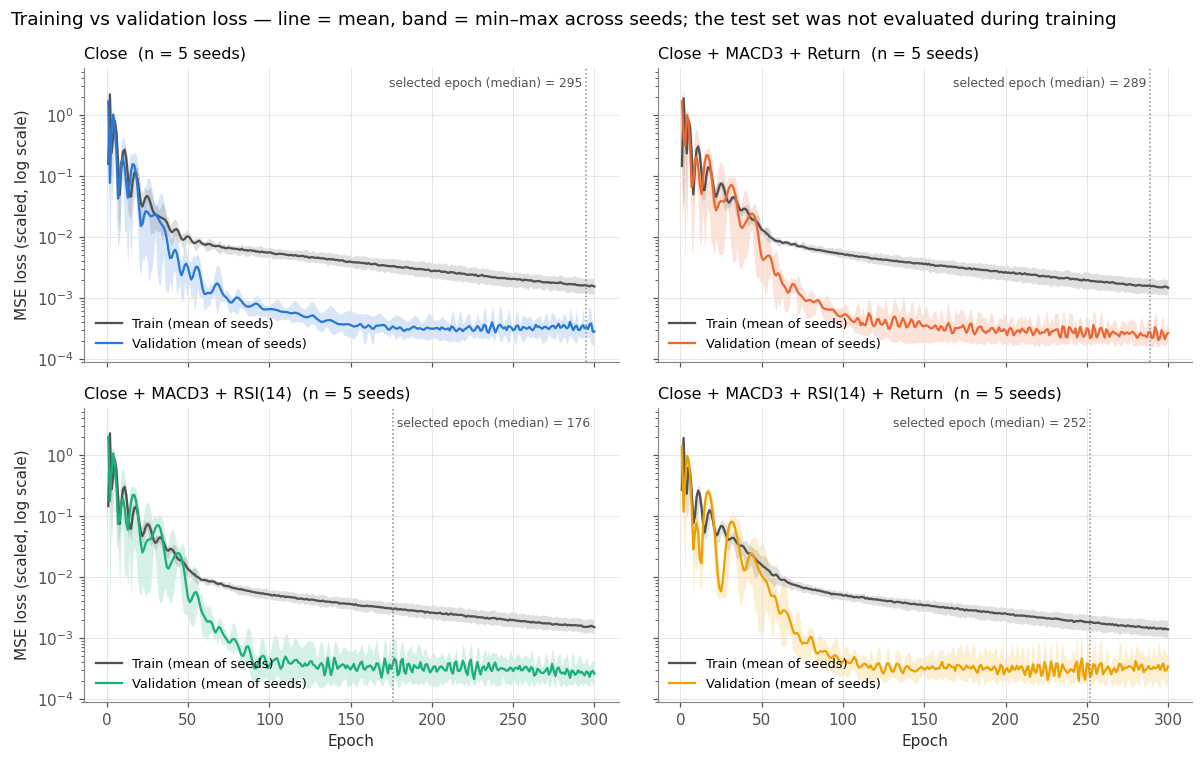

In [13]:
# ---- 圖 2：loss 曲線（對數刻度）----
SECOND_LOSS = ('val_loss', 'Validation') if USE_VAL else ('test_loss', 'Test')
fig, axes = plt.subplots(2, 2, figsize=(11, 7), sharex=True, sharey=True)
for ax, name in zip(axes.flat, PRIORITY_NAMES):
    L = losses[name]
    if L is None:
        ax.set_title(f'{name} (not run yet)', loc='left'); continue
    for col, color, label in [('train_loss', COL_TRAIN, 'Train'), (SECOND_LOSS[0], COMBO_COLORS[name], SECOND_LOSS[1])]:
        piv = L.pivot(index='epoch', columns='seed', values=col)
        ax.fill_between(piv.index, piv.min(axis=1), piv.max(axis=1), color=color, alpha=0.18, lw=0)
        ax.plot(piv.index, piv.mean(axis=1), color=color, label=f'{label} (mean of seeds)')
    if USE_VAL:
        be = runs.loc[runs.combo == name, 'best_epoch'].median()
        ax.axvline(be, color=COL_NAIVE, ls=':', lw=1)
        right = be > 0.6 * NUM_EPOCHS
        ax.text(be, 0.97, f'selected epoch (median) = {be:.0f} ' if right else f' selected epoch (median) = {be:.0f}',
                transform=ax.get_xaxis_transform(), fontsize=8, color='#52514e', va='top', ha='right' if right else 'left')
    ax.set_yscale('log')
    ax.set_title(f'{name}  (n = {L.seed.nunique()} seeds)', loc='left')
    ax.legend(loc='lower left')
for ax in axes[1]: ax.set_xlabel('Epoch')
for ax in axes[:, 0]: ax.set_ylabel('MSE loss (scaled, log scale)')
if USE_VAL:
    fig.suptitle('Training vs validation loss — line = mean, band = min–max across seeds; '
                 'the test set was not evaluated during training', x=0.01, ha='left')
else:
    fig.suptitle('Training vs test loss — line = mean, band = min–max across seeds\n'
                 'Test loss is recorded for reference only; it is not used for training or model selection.',
                 x=0.01, ha='left')
fig.tight_layout()
save(fig, '02_loss_curves_log.png')

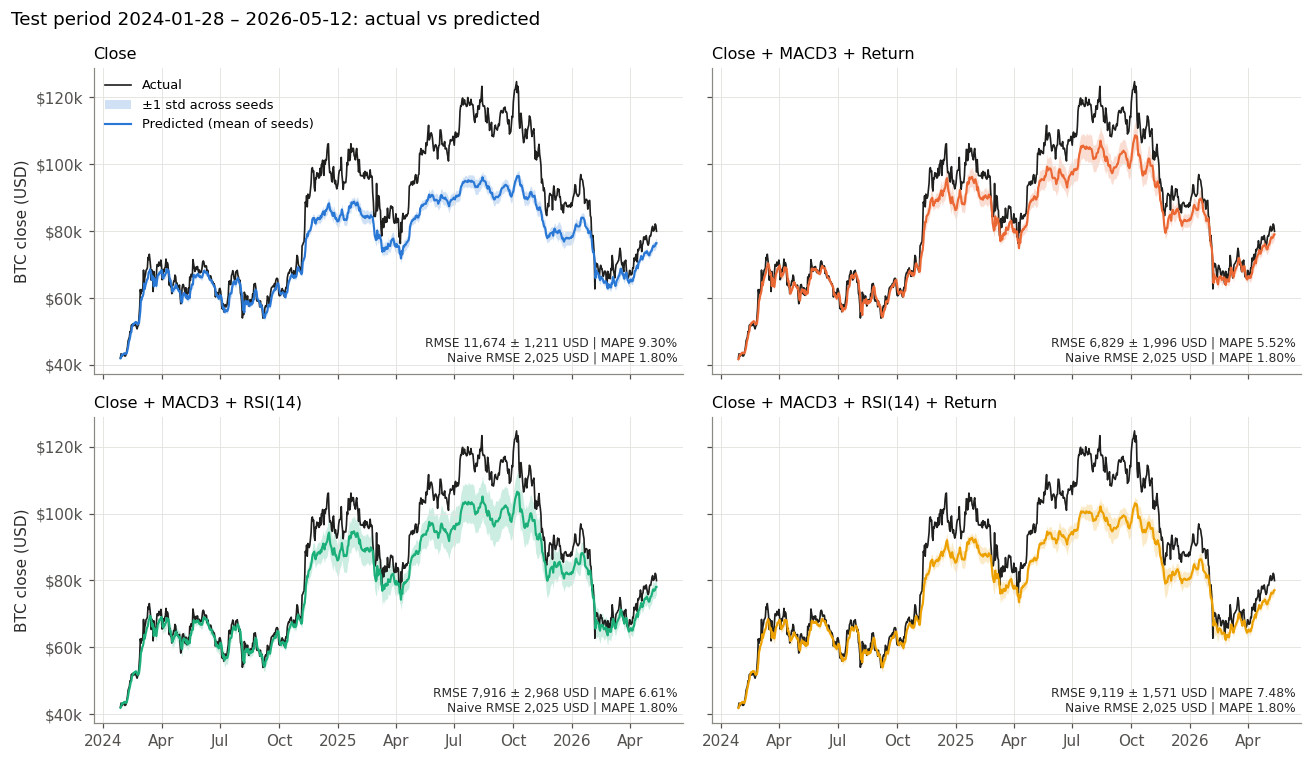

In [14]:
# ---- 圖 3：整個測試期（實際 vs 預測，seed 平均 ± 1 std）----
def note(name):
    r = summary[summary.combo == name]
    if r.empty: return ''
    r = r.iloc[0]
    return (f"RMSE {pm(r.test_RMSE_mean, r.test_RMSE_std, ',.0f')} USD | MAPE {r.test_MAPE_mean:.2f}%\n"
            f"Naive RMSE {nm['RMSE']:,.0f} USD | MAPE {nm['MAPE']:.2f}%")

fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharex=True, sharey=True)
for ax, name in zip(axes.flat, PRIORITY_NAMES):
    ax.plot(test.target_date, test.actual, color=COL_ACTUAL, lw=1.1, label='Actual')
    if f'{name} mean' in test:
        c = COMBO_COLORS[name]
        m, s = test[f'{name} mean'], test[f'{name} std'].fillna(0)
        ax.fill_between(test.target_date, m - s, m + s, color=c, alpha=0.22, lw=0, label='±1 std across seeds')
        ax.plot(test.target_date, m, color=c, lw=1.4, label='Predicted (mean of seeds)')
        ax.text(0.99, 0.03, note(name), transform=ax.transAxes, ha='right', va='bottom', fontsize=8, color='#2b2b2a')
    ax.set_title(name if f'{name} mean' in test else f'{name} (not run yet)', loc='left')
    ax.yaxis.set_major_formatter(usd_k)
    date_axis(ax)
axes[0, 0].legend(loc='upper left')
for ax in axes[:, 0]: ax.set_ylabel('BTC close (USD)')
fig.suptitle(f"Test period {split_info['test']['first_target_date']} – {split_info['test']['last_target_date']}: actual vs predicted",
             x=0.01, ha='left')
fig.tight_layout()
save(fig, '03_test_period.png')

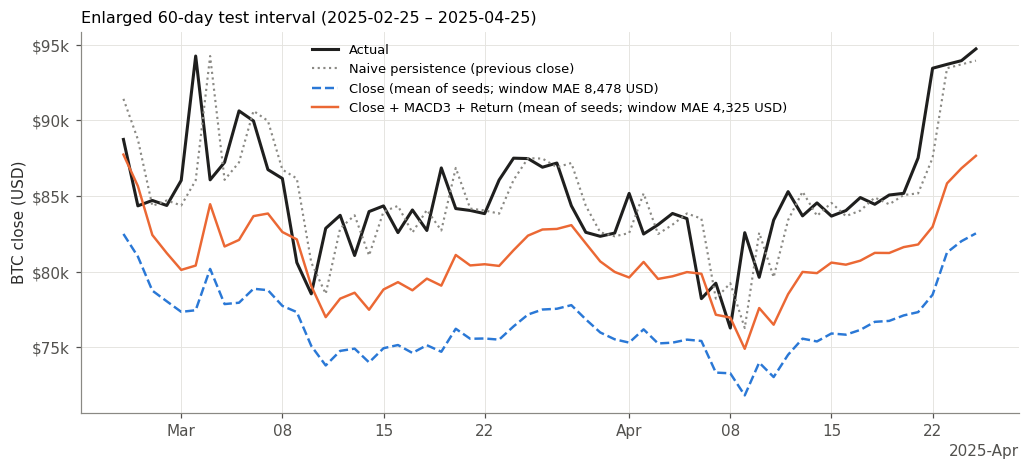

放大區間：2025-02-25 ~ 2025-04-25
                 Model  Window MAE (USD)  Mean |pred − previous close| (USD)
     Naive persistence             2,024                                   0
                 Close             8,478                               8,423
Close + MACD3 + Return             4,325                               4,080
→ 最後一欄越接近 0，代表預測越像「直接抄今天的價格」


In [15]:
# ---- 圖 4（報告 Fig. 4(c)）：測試期 60 天放大圖 ----
# 實際價格、Naive persistence、Close-only、最佳組合畫在同一張，看模型是不是只是「晚一天抄答案」
ZOOM_DAYS = 60
ZOOM_START = None    # None = 自動挑轉折最劇烈的 60 天；也可手動指定，例如 '2025-09-15'

def pick_zoom_start(t, days):
    """轉折幅度 = 區間內的高點（或低點）前後兩段漲跌幅中較小的那個；挑這個值最大的 60 天，
    也就是「先大漲再大跌」或「先大跌再大漲」最明顯的一段"""
    c, best = t.actual.values, None
    for s in range(0, len(c) - days + 1):
        w = c[s:s + days]
        i, j = w.argmax(), w.argmin()
        peak = min(w[i] - w[:i + 1].min(), w[i] - w[i:].min())      # 先漲後跌
        trough = min(w[:j + 1].max() - w[j], w[j:].max() - w[j])    # 先跌後漲
        score = max(peak, trough) / w.mean()
        if best is None or score > best[0]:
            best = (score, s)
    return best[1]

z0 = (int(np.searchsorted(test.target_date.values, np.datetime64(ZOOM_START))) if ZOOM_START
      else pick_zoom_start(test, ZOOM_DAYS))
z = test.iloc[z0:z0 + ZOOM_DAYS]
zoom_from, zoom_to = f'{z.target_date.iloc[0]:%Y-%m-%d}', f'{z.target_date.iloc[-1]:%Y-%m-%d}'

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(z.target_date, z.actual, color=COL_ACTUAL, lw=2, label='Actual')
ax.plot(z.target_date, z.naive, color=COL_NAIVE, lw=1.4, ls=':', label='Naive persistence (previous close)')
zoom_stats = [('Naive persistence', calc_metrics(z.actual, z.naive)['MAE'], 0.0)]
for name, ls in [(BASE_NAME, '--'), (BEST_NAME, '-')]:
    if f'{name} mean' in z:
        mae = calc_metrics(z.actual, z[f'{name} mean'])['MAE']
        gap = float(np.mean(np.abs(z[f'{name} mean'] - z.naive)))
        zoom_stats.append((name, mae, gap))
        ax.plot(z.target_date, z[f'{name} mean'], color=COMBO_COLORS[name], lw=1.6, ls=ls,
                label=f'{name} (mean of seeds; window MAE {mae:,.0f} USD)')
ax.yaxis.set_major_formatter(usd_k)
ax.set_ylabel('BTC close (USD)')
date_axis(ax)
ax.set_title(f'Enlarged {ZOOM_DAYS}-day test interval ({zoom_from} – {zoom_to})', loc='left')
ax.legend(loc='best')
save(fig, '04_test_zoom_60d.png')

print(f'放大區間：{zoom_from} ~ {zoom_to}')
print(pd.DataFrame(zoom_stats, columns=['Model', 'Window MAE (USD)', 'Mean |pred − previous close| (USD)'])
      .to_string(index=False, float_format=lambda v: f'{v:,.0f}'))
print('→ 最後一欄越接近 0，代表預測越像「直接抄今天的價格」')

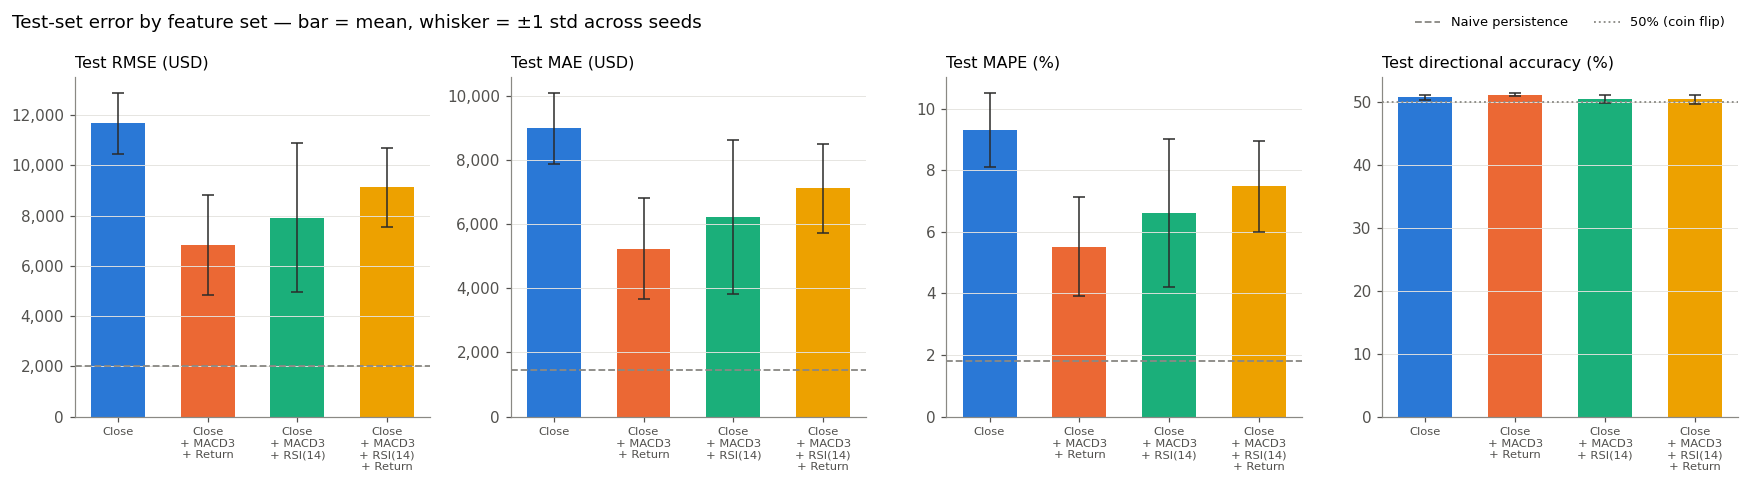

In [16]:
# ---- 圖 5：四個優先組合的測試指標（平均 ± 1 std）vs Naive ----
avail = [n for n in PRIORITY_NAMES if n in set(summary.combo)]
sub = summary.set_index('combo').loc[avail]
x = np.arange(len(avail))
fig, axes = plt.subplots(1, 4, figsize=(16, 4.4))
for ax, m in zip(axes, ['RMSE', 'MAE', 'MAPE', 'DirAcc']):
    ax.bar(x, sub[f'test_{m}_mean'], yerr=sub[f'test_{m}_std'].fillna(0), width=0.6, capsize=4,
           color=[COMBO_COLORS[n] for n in avail], error_kw=dict(lw=1, ecolor='#2b2b2a'))
    if m == 'DirAcc':
        ax.axhline(50, color=COL_NAIVE, ls=':', lw=1.2, label='50% (coin flip)')
        ax.set_title('Test directional accuracy (%)', loc='left')
    else:
        ax.axhline(nm[m], color=COL_NAIVE, ls='--', lw=1.2, label='Naive persistence')
        ax.set_title(f"Test {m} ({'%' if m == 'MAPE' else 'USD'})", loc='left')
    ax.set_xticks(x, [wrap(n) for n in avail], fontsize=7.5)
    ax.grid(axis='x', visible=False)
    if m in ('RMSE', 'MAE'):
        ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f'{v:,.0f}'))
h0, l0 = axes[0].get_legend_handles_labels()
h3, l3 = axes[3].get_legend_handles_labels()
fig.legend(h0 + h3, l0 + l3, loc='upper right', bbox_to_anchor=(0.99, 1.0), ncol=2)
fig.suptitle('Test-set error by feature set — bar = mean, whisker = ±1 std across seeds', x=0.01, ha='left')
fig.tight_layout()
save(fig, '05_metrics_priority.png')

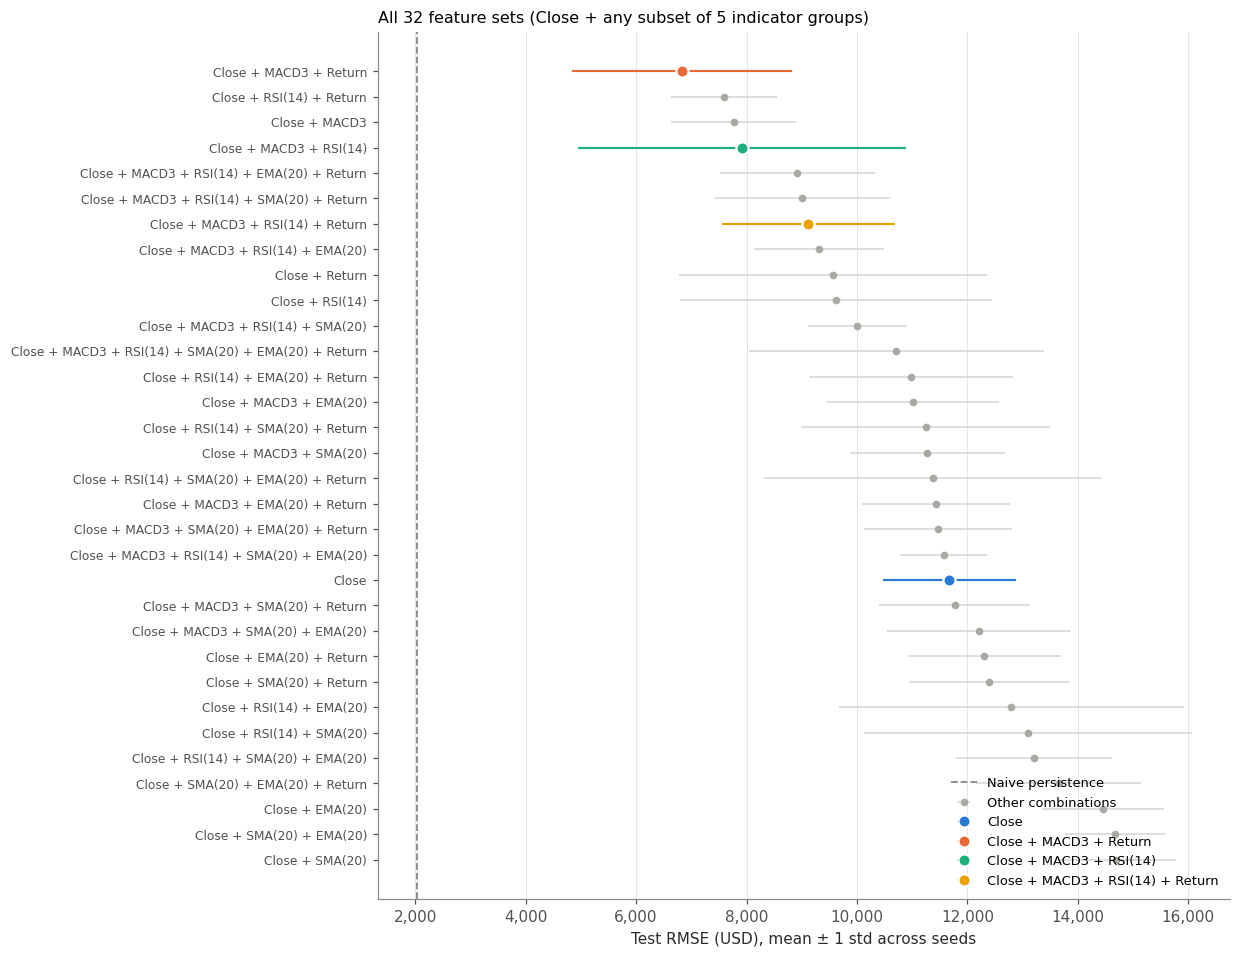

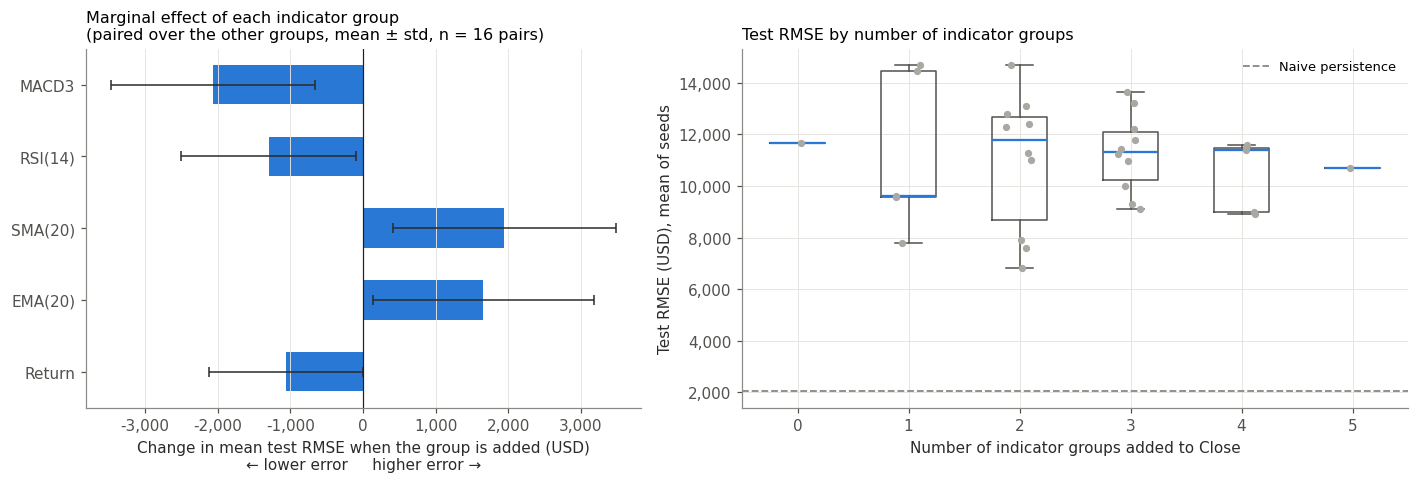

In [17]:
# ---- 圖 6–7：全部 32 組（跑完 RUN_SCOPE = 'all' 後才完整）----
if len(summary) <= len(PRIORITY_NAMES):
    print("目前只有優先組合的結果；RUN_SCOPE = 'all' 跑完後再執行這格。")
else:
    # 圖 6：全部組合的 test RMSE（依平均排序）
    s6 = summary.sort_values('test_RMSE_mean', ascending=False).reset_index(drop=True)
    fig, ax = plt.subplots(figsize=(10, 0.27 * len(s6) + 1.6))
    yy = np.arange(len(s6))
    is_pri = s6.combo.isin(PRIORITY_NAMES)
    ax.errorbar(s6.loc[~is_pri, 'test_RMSE_mean'], yy[~is_pri], xerr=s6.loc[~is_pri, 'test_RMSE_std'].fillna(0),
                fmt='o', ms=4, color=COL_OTHER, ecolor='#d6d5cf', elinewidth=1, label='Other combinations')
    for name in PRIORITY_NAMES:
        i = s6.index[s6.combo == name]
        if len(i):
            r = s6.loc[i[0]]
            ax.errorbar(r.test_RMSE_mean, i[0], xerr=0 if pd.isna(r.test_RMSE_std) else r.test_RMSE_std,
                        fmt='o', ms=8, color=COMBO_COLORS[name], mec='white', mew=1.5,
                        ecolor=COMBO_COLORS[name], elinewidth=1.4, label=name, zorder=5)
    ax.axvline(nm['RMSE'], color=COL_NAIVE, ls='--', lw=1.2, label='Naive persistence')
    ax.set_yticks(yy, [n + ('' if k >= len(SEEDS) else ' †') for n, k in zip(s6.combo, s6.n_seeds)], fontsize=8)
    ax.set_xlabel('Test RMSE (USD), mean ± 1 std across seeds')
    ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f'{v:,.0f}'))
    ax.set_title(f'All {len(s6)} feature sets (Close + any subset of 5 indicator groups)', loc='left')
    ax.grid(axis='y', visible=False)
    ax.legend(loc='lower right')
    save(fig, '06_all_combos_rmse.png')

    # 圖 7：每組指標的邊際效果（配對比較）+ 指標組數
    rmse = dict(zip(summary.combo, summary.test_RMSE_mean))
    rows = []
    for gs in ALL_COMBOS:
        for g in GROUP_ORDER:
            if g in gs: continue
            a, b = combo_name(gs), combo_name(gs + [g])
            if a in rmse and b in rmse:
                rows.append({'group': g, 'delta': rmse[b] - rmse[a]})
    eff = (pd.DataFrame(rows).groupby('group')['delta'].agg(['mean', 'std', 'count'])
             .reindex(GROUP_ORDER).dropna(subset=['mean']))
    eff.to_csv(OUT_DIR / 'group_marginal_effect.csv')

    fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4.5), gridspec_kw={'width_ratios': [1, 1.2]})
    yy = np.arange(len(eff))
    a1.barh(yy, eff['mean'], xerr=eff['std'], color='#2a78d6', height=0.55, capsize=3, error_kw=dict(lw=1, ecolor='#2b2b2a'))
    a1.axvline(0, color=COL_ACTUAL, lw=0.8)
    a1.set_yticks(yy, eff.index); a1.invert_yaxis()
    a1.set_xlabel('Change in mean test RMSE when the group is added (USD)\n← lower error     higher error →')
    a1.set_title(f'Marginal effect of each indicator group\n(paired over the other groups, mean ± std, n = {int(eff["count"].max())} pairs)', loc='left')
    a1.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f'{v:,.0f}'))
    a1.grid(axis='y', visible=False)

    groups_k = [summary.loc[summary.n_groups == k, 'test_RMSE_mean'].values for k in range(len(GROUP_ORDER) + 1)]
    a2.boxplot(groups_k, positions=range(len(groups_k)), widths=0.5, showfliers=False,
               medianprops=dict(color='#2a78d6', lw=1.5), boxprops=dict(color='#52514e'),
               whiskerprops=dict(color='#52514e'), capprops=dict(color='#52514e'))
    rng = np.random.default_rng(0)
    for k, g in enumerate(groups_k):
        a2.scatter(k + rng.uniform(-0.12, 0.12, len(g)), g, s=14, color=COL_OTHER, zorder=3)
    a2.axhline(nm['RMSE'], color=COL_NAIVE, ls='--', lw=1.2, label='Naive persistence')
    a2.set_xlabel('Number of indicator groups added to Close')
    a2.set_ylabel('Test RMSE (USD), mean of seeds')
    a2.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f'{v:,.0f}'))
    a2.set_title('Test RMSE by number of indicator groups', loc='left')
    a2.legend(loc='best')
    fig.tight_layout()
    save(fig, '07_group_effect.png')

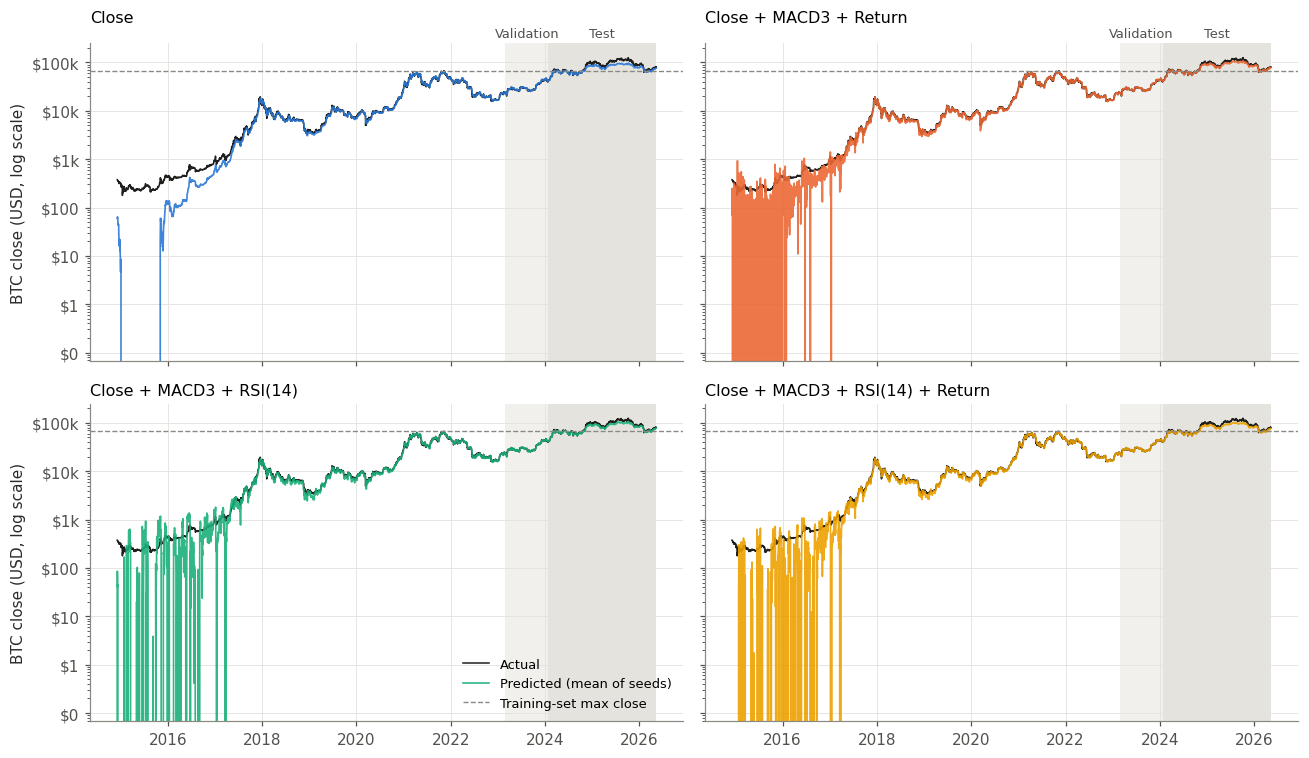

In [18]:
# ---- 圖 8（報告 Fig. 4(a)(b)）：全期間實際 vs 預測，x 軸為日期 ----
fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharex=True, sharey=True)
for ax, name in zip(axes.flat, PRIORITY_NAMES):
    shade_splits(ax, label=(ax in axes[0]))
    ax.plot(full.target_date, full.actual, color=COL_ACTUAL, lw=1.0, label='Actual')
    if f'{name} mean' in full:
        ax.plot(full.target_date, full[f'{name} mean'], color=COMBO_COLORS[name], lw=1.1, alpha=0.9,
                label='Predicted (mean of seeds)')
    ax.axhline(train_max, color=COL_NAIVE, ls='--', lw=0.9, label='Training-set max close')
    ax.set_yscale('log')
    ax.yaxis.set_major_formatter(usd_k)
    ax.set_title(name, loc='left', pad=14 if ax in axes[0] else 6)
    date_axis(ax)
axes[1, 0].legend(loc='lower right')
for ax in axes[:, 0]: ax.set_ylabel('BTC close (USD, log scale)')
fig.tight_layout()
save(fig, '08_full_period.png')

## 產出檔案一覽（Google Drive：`btc_transformer_results/v3_split_72-8-20/`）

| 檔案 | 內容 | 報告用途 |
|---|---|---|
| `table2_settings.csv` | 實驗設定（含預熱期刪除天數、batch、seed、版本、GPU） | Table II（#5） |
| `table4_ten_configs.csv` | 報告的 10 組 + Naive，平均 ± SD、範圍、MAPE、方向命中率 | Table IV（#1、#3、#6、#15） |
| `table_all_32_configs.csv` | 32 組 + Naive | 附錄 / 補充 |
| `comparisons.csv` | 老師指定的比較：明顯較好或 comparable、paired t-test | 第 3 項的改寫句 |
| `metrics_summary_all.csv` | 每組各 split 的所有指標（平均、SD、最小、最大、最高預測值） | 第 8 項數字 |
| `runs_metrics.csv` | 每一次實驗（組合 × seed）的結果 | 原始紀錄 |
| `split_info.json` | 資料期間、切分日期與天數、各段最高價 | 第 8 項、Fig. 2 圖說 |
| `environment_log.jsonl` | GPU、CUDA、套件版本 | Table II |
| `naive_baseline_predictions.csv`、`test_predictions_wide.csv`、`predictions_*.csv` | 逐日預測 | 第 4 點的逐日資料 |
| `predictions/`、`loss/` | 每次實驗的逐日預測、每個 epoch 的 loss | 原始紀錄 |
| `figures/` | 01 切分、02 loss（Fig. 5）、03 測試期、04 60 天放大（Fig. 4(c)）、05 指標、06 全部組合、07 指標組效果、08 全期間（Fig. 4(a)(b)） | |